# Customer Churn Prediction
### Project 02 | Machine Learning Portfolio Project
**Author:** Beginner Data Scientist  
**Dataset:** IBM Telco Customer Churn (`Telco-Customer-Churn.csv`)  
**Domain:** Telecommunications & Customer Retention

---

## Business Problem & Objective
In the telecommunications industry, customer retention is far more profitable than customer acquisition. Studies show that acquiring a new customer costs 5 to 25 times more than retaining an existing customer. When a customer cancels their service, the business loses steady recurring revenue and future customer lifetime value (LTV).

**Objective:**  
Build an end-to-end Machine Learning classification project to predict which customers are likely to churn (leave the company). This enables the customer retention team to intervene proactively with personalized offers, discounts, or service improvements before the customer leaves.

---

## Complete Project Workflow (22 Steps)
1. **Import Libraries** - Import essential Data Science and ML libraries
2. **Load Dataset** - Load `Telco-Customer-Churn.csv` into a Pandas DataFrame
3. **Dataset Preview** - Inspect rows and columns using `head()`, `tail()`, `shape`, `columns`
4. **Dataset Information** - Examine data types, non-null counts, and statistical summaries using `info()` and `describe()`
5. **Check Missing Values** - Identify missing and null records per column
6. **Check Duplicate Values** - Identify and remove duplicate records
7. **Basic Data Cleaning** - Strip extra spaces, fix `TotalCharges` type & missing values, and drop `customerID`
8. **Exploratory Data Analysis (EDA)** - Calculate overall churn rate and feature averages
9. **Data Visualization** - Visualize churn patterns across 6 key customer demographics and service features
10. **Encoding** - Label Encode the target variable (`Churn`) and One-Hot Encode categorical features (`pd.get_dummies`)
11. **Train-Test Split** - Split data into 80% training and 20% testing sets with stratification (`stratify=y`)
12. **Logistic Regression** - Train a baseline Logistic Regression model and generate predictions
13. **Decision Tree Classifier** - Train a baseline Decision Tree model and generate predictions
14. **Cross-Validation** - Evaluate model stability using 5-Fold Cross-Validation (`cross_val_score`)
15. **Hyperparameter Tuning** - Explain model parameters vs hyperparameters and why tuning matters
16. **GridSearchCV** - Optimize Logistic Regression regularization parameter `C`
17. **RandomizedSearchCV** - Optimize Decision Tree `max_depth` and `min_samples_split`
18. **Model Accuracy** - Calculate and verify test set accuracy for all 4 model variants
19. **Confusion Matrix** - Generate confusion matrices and explain TP, TN, FP, FN in churn context
20. **Classification Report** - Evaluate Precision, Recall, F1-Score, and Support for all models
21. **Model Comparison** - Compare all models in a summary DataFrame, plot accuracy, and explain why accuracy alone is insufficient
22. **Project Conclusion** - Summarize final results, choose the best model, and outline actionable business recommendations


## 1. Import Libraries

Before starting our analysis, we import only the necessary Python libraries:
* **pandas (`pd`)**: Used for structured data manipulation and DataFrame operations.
* **numpy (`np`)**: Used for numerical computations and array operations.
* **matplotlib.pyplot (`plt`)**: Foundational library for creating data visualizations.
* **seaborn (`sns`)**: High-level statistical visualization library with aesthetically pleasing default styles.
* **sklearn.model_selection**: Provides `train_test_split`, `cross_val_score`, `GridSearchCV`, and `RandomizedSearchCV`.
* **sklearn.preprocessing**: Provides `LabelEncoder` for encoding our target variable.
* **sklearn.linear_model**: Provides `LogisticRegression`.
* **sklearn.tree**: Provides `DecisionTreeClassifier`.
* **sklearn.metrics**: Provides evaluation metrics (`accuracy_score`, `confusion_matrix`, `classification_report`, `ConfusionMatrixDisplay`).
* **warnings**: Used to suppress non-critical deprecation and convergence warnings to keep our notebook clean.


In [1]:
# 1. Import Required Libraries
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-Learn tools for modeling and evaluation
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, confusion_matrix, classification_report, 
    ConfusionMatrixDisplay, precision_score, recall_score, f1_score
)

# Set visual styling for charts
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', None)

print("Libraries imported successfully.")


Libraries imported successfully.


## 2. Load Dataset

We load the Telco Customer Churn dataset from the local CSV file `Telco-Customer-Churn.csv` using Pandas `pd.read_csv()`.

The dataset contains customer demographic information, account information, subscribed telecom services, monthly spending, and whether the customer churned (`Yes` or `No`).


In [2]:
# 2. Load the Dataset
df = pd.read_csv("Telco-Customer-Churn.csv")

print("Dataset loaded successfully!")
print(f"Total Rows: {df.shape[0]:,}")
print(f"Total Columns: {df.shape[1]}")


Dataset loaded successfully!
Total Rows: 7,043
Total Columns: 21


## 3. Dataset Preview

To get an initial understanding of the data structure, we preview the first few rows, last few rows, dimensions, and column names:
* **`head()`**: Displays the first 5 records.
* **`tail()`**: Displays the last 5 records.
* **`shape`**: Displays the tuple `(number_of_rows, number_of_columns)`.
* **`columns`**: Lists all 21 column names in the dataset.


In [3]:
# Preview the first 5 rows
print("--- First 5 Rows (head) ---")
df.head()


--- First 5 Rows (head) ---


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
# Preview the last 5 rows
print("--- Last 5 Rows (tail) ---")
df.tail()


--- Last 5 Rows (tail) ---


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,No,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


In [5]:
# Dataset dimensions and column list
print("--- Dataset Shape ---")
print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}")

print("\n--- Column Names ---")
print(list(df.columns))


--- Dataset Shape ---
Rows: 7043, Columns: 21

--- Column Names ---
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


## 4. Dataset Information

We inspect the dataset structure using:
* **`info()`**: Summarizes column names, non-null counts, data types (`int64`, `float64`, `object`), and memory usage.
* **`describe()`**: Computes summary statistics for numeric features (count, mean, standard deviation, min, 25%, 50%, 75%, max) and categorical features.


In [6]:
# Summary information of columns and data types
print("--- Dataset Information (info) ---")
df.info()


--- Dataset Information (info) ---
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  

In [7]:
# Statistical summary of numerical columns
print("--- Statistical Summary: Numerical Columns ---")
df.describe()


--- Statistical Summary: Numerical Columns ---


,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [8]:
# Statistical summary of categorical columns
print("--- Statistical Summary: Categorical Columns ---")
df.describe(include='object')


--- Statistical Summary: Categorical Columns ---


,customerID,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,TotalCharges,Churn
count,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043
unique,7043,2,2,2,2,3,3,3,3,3,3,3,3,3,2,4,6531,2
top,7590-VHVEG,Male,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,20.2,No
freq,1,3555,3641,4933,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,11,5174


## 5. Check Missing Values

Missing data is common in real-world datasets. In machine learning, missing values can cause algorithms to fail or produce biased predictions.

We use `df.isnull().sum()` to count the number of null (`NaN`) values in every column.

> **Important Note:** In the raw dataset, notice that `TotalCharges` has data type `object` (string text). This is because missing entries were recorded as blank whitespace characters (`" "`) instead of formal `NaN` values. We will uncover and fix this in the data cleaning section below!


In [9]:
# Check missing values per column
print("--- Missing Values per Column ---")
print(df.isnull().sum())


--- Missing Values per Column ---
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


## 6. Check Duplicate Values

Duplicate records occur when the exact same customer information is recorded multiple times. Duplicates can lead to data leakage and artificially inflate training performance.

We check for duplicates using `df.duplicated().sum()` and drop any duplicate rows using `df.drop_duplicates()`.


In [10]:
# Check for duplicate records
duplicate_count = df.duplicated().sum()
print(f"Number of duplicate records found: {duplicate_count}")

if duplicate_count > 0:
    df.drop_duplicates(inplace=True)
    print("Duplicate records removed.")
else:
    print("No duplicate records exist in the dataset.")


Number of duplicate records found: 0
No duplicate records exist in the dataset.


## 7. Basic Data Cleaning

Data cleaning is one of the most critical steps in machine learning. Clean data ensures models learn true patterns rather than noise.

In this section, we perform four essential cleaning steps:
1. **Remove unnecessary whitespace**: Strip leading and trailing spaces from all text columns.
2. **Convert `TotalCharges` to numeric**: Use `pd.to_numeric()` with `errors='coerce'`. Any blank spaces (`" "`) will be converted into proper `NaN` (missing values).
3. **Handle missing values**: Check the rows where `TotalCharges` became `NaN`. We will find that these customers have `tenure == 0` (brand-new customers who haven't completed their first billing cycle yet). Therefore, their total charge is logically **`0`**. We fill these 11 missing values with `0`.
4. **Remove `customerID`**: `customerID` is an arbitrary unique string identifier (e.g., `"7590-VHVEG"`). It carries no predictive business signal and would only cause the model to memorize random strings or overfit.


In [11]:
# 1. Strip leading and trailing whitespace from string columns
object_columns = df.select_dtypes(include='object').columns
for col in object_columns:
    df[col] = df[col].astype(str).str.strip()

# 2. Convert TotalCharges into numeric format
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print(f"Missing values in TotalCharges after numeric conversion: {df['TotalCharges'].isnull().sum()}")

# Inspect the rows with missing TotalCharges
print("\nCustomers with missing TotalCharges (tenure is 0):")
print(df[df['TotalCharges'].isnull()][['tenure', 'MonthlyCharges', 'TotalCharges']].head())

# 3. Handle missing values: fill with 0 since tenure is 0
df['TotalCharges'] = df['TotalCharges'].fillna(0)
print(f"\nMissing values in TotalCharges after filling with 0: {df['TotalCharges'].isnull().sum()}")

# 4. Remove customerID column from model features
if 'customerID' in df.columns:
    df.drop(columns=['customerID'], inplace=True)
    print("customerID column successfully removed from features.")

print(f"\nCleaned Dataset Shape: {df.shape}")


Missing values in TotalCharges after numeric conversion: 11

Customers with missing TotalCharges (tenure is 0):
      tenure  MonthlyCharges  TotalCharges
488        0           52.55           NaN
753        0           20.25           NaN
936        0           80.85           NaN
1082       0           25.75           NaN
1340       0           56.05           NaN

Missing values in TotalCharges after filling with 0: 0
customerID column successfully removed from features.

Cleaned Dataset Shape: (7043, 20)


## 8. Exploratory Data Analysis (EDA)

Exploratory Data Analysis helps us understand customer behavior and distributions before modeling.

We examine:
1. The overall **churn rate**: What percentage of customers have left the company?
2. Group comparisons: How do tenure, monthly charges, and total charges differ between customers who churned and those who stayed?


In [12]:
# Calculate churn distribution
churn_counts = df['Churn'].value_counts()
churn_percentages = (df['Churn'].value_counts(normalize=True) * 100).round(2)

print("--- Churn Counts ---")
print(churn_counts)
print("\n--- Churn Percentages ---")
print(churn_percentages)

print("\n--- Average Numerical Values by Churn Status ---")
print(df.groupby('Churn')[['tenure', 'MonthlyCharges', 'TotalCharges']].mean().round(2))


--- Churn Counts ---
Churn
No     5174
Yes    1869
Name: count, dtype: int64

--- Churn Percentages ---
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64

--- Average Numerical Values by Churn Status ---
       tenure  MonthlyCharges  TotalCharges
Churn                                      
No      37.57           61.27       2549.91
Yes     17.98           74.44       1531.80


### Key Takeaways from EDA:
1. **Class Imbalance**: Around **73.46%** of customers stayed (`No`), while **26.54%** churned (`Yes`). This is a moderately imbalanced binary classification dataset.
2. **Tenure**: Churned customers have a much shorter average tenure (**17.98 months**) compared to retained customers (**37.57 months**). New customers are at the highest risk of leaving!
3. **Monthly Charges**: Churned customers pay significantly higher average monthly charges (**$74.44**) compared to retained customers (**$61.27**). High monthly bills are a clear driver of dissatisfaction.


## 9. Data Visualization

Visualizations make data patterns intuitive and easy to explain during interviews. We create beginner-friendly Seaborn and Matplotlib visualizations for the six key business relationships:
1. **Churn Distribution**: Visualizing class balance between Churned vs Retained customers.
2. **Gender vs Churn**: Checking if gender affects churn propensity.
3. **Contract vs Churn**: Analyzing churn across Month-to-Month, One-Year, and Two-Year contracts.
4. **Tenure Distribution**: Examining customer longevity and attrition timing.
5. **Monthly Charges vs Churn**: Comparing monthly spending distributions for churned vs non-churned customers.
6. **Payment Method vs Churn**: Identifying high-risk payment methods.


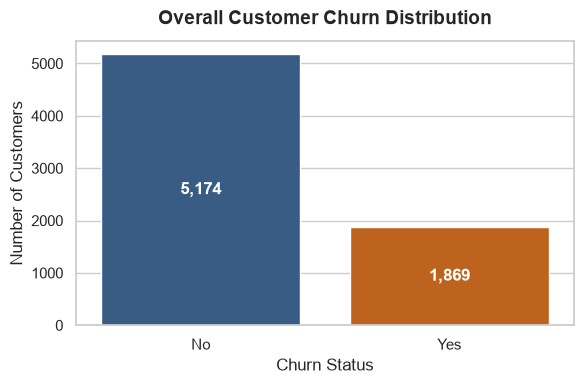

In [13]:
# 9.1 Churn Distribution
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(x='Churn', data=df, palette=['#2b5c8f', '#d95f02'], ax=ax)
ax.set_title("Overall Customer Churn Distribution", fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel("Churn Status", fontsize=12)
ax.set_ylabel("Number of Customers", fontsize=12)

# Add counts on top of bars
for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}", 
                (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                ha='center', va='center', color='white', fontweight='bold', fontsize=12)

plt.tight_layout()
plt.show()


**Insight from Churn Distribution:**
Out of 7,043 customers, 5,174 stayed (73.5%) and 1,869 churned (26.5%). Because the non-churn class is almost 3 times larger than the churn class, evaluating models using accuracy alone would be misleading.


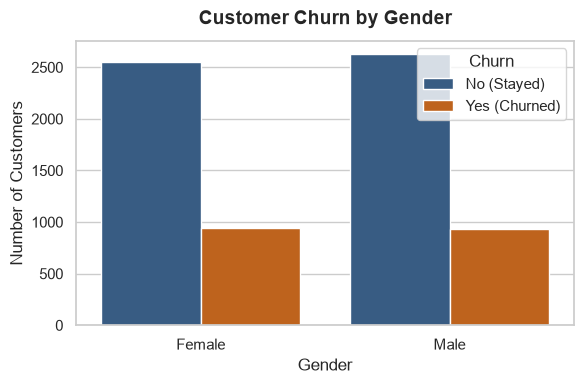

In [14]:
# 9.2 Gender vs Churn
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(x='gender', hue='Churn', data=df, palette=['#2b5c8f', '#d95f02'], ax=ax)
ax.set_title("Customer Churn by Gender", fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel("Gender", fontsize=12)
ax.set_ylabel("Number of Customers", fontsize=12)
ax.legend(title="Churn", labels=["No (Stayed)", "Yes (Churned)"])

plt.tight_layout()
plt.show()


**Insight from Gender vs Churn:**
The churn rate is virtually identical between Male and Female customers (~26% for both). Gender is not a distinguishing feature for customer retention.


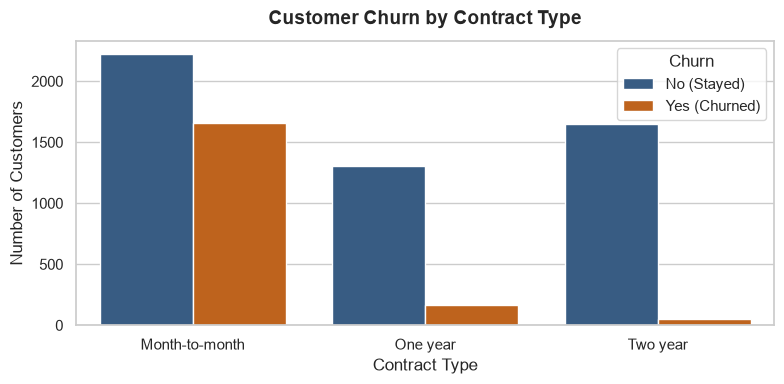

In [15]:
# 9.3 Contract vs Churn
fig, ax = plt.subplots(figsize=(8, 4))
sns.countplot(x='Contract', hue='Churn', data=df, palette=['#2b5c8f', '#d95f02'], ax=ax)
ax.set_title("Customer Churn by Contract Type", fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel("Contract Type", fontsize=12)
ax.set_ylabel("Number of Customers", fontsize=12)
ax.legend(title="Churn", labels=["No (Stayed)", "Yes (Churned)"])

plt.tight_layout()
plt.show()


**Insight from Contract vs Churn:**
Contract type is one of the strongest predictors of churn:
* **Month-to-Month** contracts exhibit an extremely high churn rate (~42%).
* **One-Year** and **Two-Year** contracts have very low churn (< 11% and < 3%). Customers with long-term contracts are heavily committed to the service.


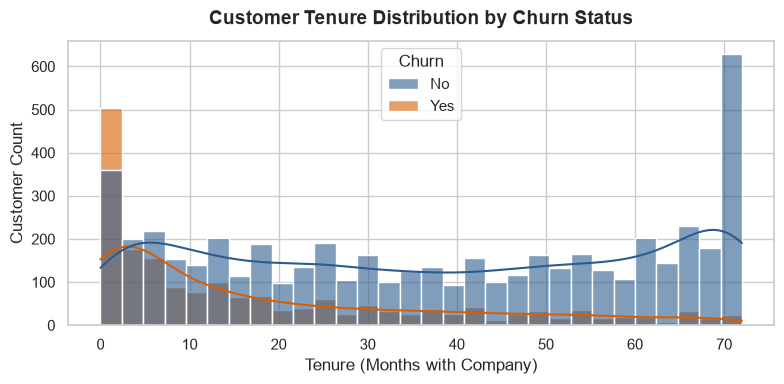

In [16]:
# 9.4 Tenure Distribution
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(data=df, x='tenure', hue='Churn', kde=True, bins=30, palette=['#2b5c8f', '#d95f02'], alpha=0.6)
ax.set_title("Customer Tenure Distribution by Churn Status", fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel("Tenure (Months with Company)", fontsize=12)
ax.set_ylabel("Customer Count", fontsize=12)

plt.tight_layout()
plt.show()


**Insight from Tenure Distribution:**
* Churn peaks dramatically in the first **1 to 6 months** of customer tenure.
* Once a customer stays past 24–36 months, their likelihood of leaving drops drastically. Retention efforts must focus on early onboarding!


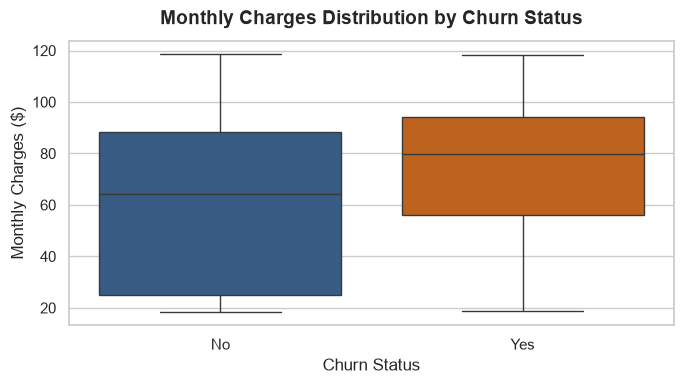

In [17]:
# 9.5 Monthly Charges vs Churn
fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(x='Churn', y='MonthlyCharges', data=df, palette=['#2b5c8f', '#d95f02'], ax=ax)
ax.set_title("Monthly Charges Distribution by Churn Status", fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel("Churn Status", fontsize=12)
ax.set_ylabel("Monthly Charges ($)", fontsize=12)

plt.tight_layout()
plt.show()


**Insight from Monthly Charges vs Churn:**
Customers who churn have significantly higher median monthly charges (~$80/month) compared to customers who stay (~$65/month). High recurring pricing without perceived value is a primary churn catalyst.


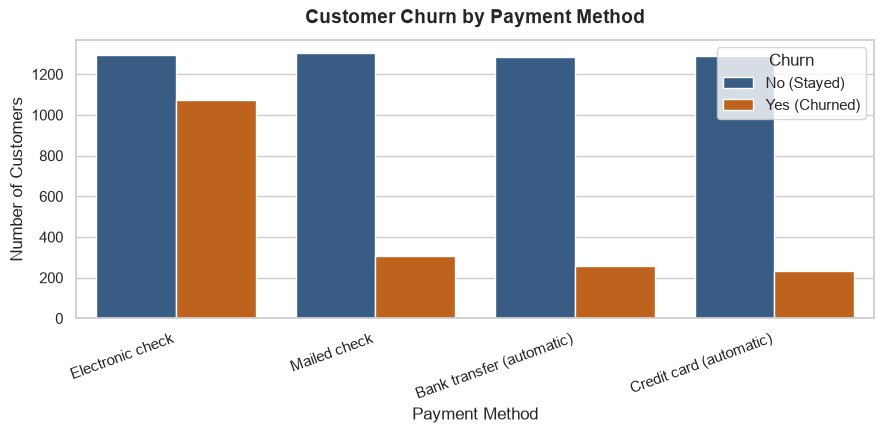

In [18]:
# 9.6 Payment Method vs Churn
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.countplot(x='PaymentMethod', hue='Churn', data=df, palette=['#2b5c8f', '#d95f02'], ax=ax)
ax.set_title("Customer Churn by Payment Method", fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel("Payment Method", fontsize=12)
ax.set_ylabel("Number of Customers", fontsize=12)
ax.legend(title="Churn", labels=["No (Stayed)", "Yes (Churned)"])
plt.xticks(rotation=20, ha='right')

plt.tight_layout()
plt.show()


**Insight from Payment Method vs Churn:**
Customers paying with **Electronic Check** churn at a much higher rate (~45%) than those using Bank Transfer, Credit Card (automatic), or Mailed Check (~15–18%). Promoting automatic billing methods can directly reduce churn.


## 10. Encoding Categorical Variables

Machine learning algorithms perform mathematical computations (matrix multiplications, distance metrics, derivatives). Therefore, all text and categorical features must be converted into numerical values.

We apply two standard encoding techniques:
1. **Label Encoding for Target Variable (`Churn`)**:
   * Binary classification target has two labels: `"No"` and `"Yes"`.
   * We encode: `"No"` $\rightarrow$ `0` and `"Yes"` $\rightarrow$ `1` using `LabelEncoder`.
2. **One-Hot Encoding for Categorical Features**:
   * For features like `Contract`, `PaymentMethod`, `InternetService`, we create binary dummy indicator columns (0 or 1).
   * We use `pd.get_dummies(df, drop_first=True)`.
   * **Why `drop_first=True`?** It drops the first category for each feature to avoid the **Dummy Variable Trap** (multicollinearity), where one dummy column can be perfectly predicted from the others. This is essential for linear models like Logistic Regression.


In [19]:
# 1. Label Encoding for Target Variable ('Churn')
le = LabelEncoder()
df['Churn'] = le.fit_transform(df['Churn'])

print("Target variable 'Churn' encoded successfully:")
print("0 -> No (Customer Stayed)")
print("1 -> Yes (Customer Churned)")
print(f"Target distribution:\n{df['Churn'].value_counts()}")

# 2. One-Hot Encoding for Categorical Features
df_encoded = pd.get_dummies(df, drop_first=True)

print(f"\nOriginal dataset shape: {df.shape}")
print(f"Encoded dataset shape:  {df_encoded.shape}")
print(f"Number of new binary features created: {df_encoded.shape[1] - df.shape[1]}")

print("\nPreview of encoded dataset:")
df_encoded.head()


Target variable 'Churn' encoded successfully:
0 -> No (Customer Stayed)
1 -> Yes (Customer Churned)
Target distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64

Original dataset shape: (7043, 20)
Encoded dataset shape:  (7043, 31)
Number of new binary features created: 11

Preview of encoded dataset:


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,InternetService_Fiber optic,InternetService_No,OnlineSecurity_No internet service,OnlineSecurity_Yes,OnlineBackup_No internet service,OnlineBackup_Yes,DeviceProtection_No internet service,DeviceProtection_Yes,TechSupport_No internet service,TechSupport_Yes,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,False,True,False,False,True,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,True,False,True,False
1,0,34,56.95,1889.50,0,True,False,False,True,False,False,False,False,False,True,False,False,False,True,False,False,False,False,False,False,True,False,False,False,False,True
2,0,2,53.85,108.15,1,True,False,False,True,False,False,False,False,False,True,False,True,False,False,False,False,False,False,False,False,False,False,True,False,False,True
3,0,45,42.30,1840.75,0,True,False,False,False,True,False,False,False,False,True,False,False,False,True,False,True,False,False,False,False,True,False,False,False,False,False
4,0,2,70.70,151.65,1,False,False,False,True,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,True,False


## 11. Train-Test Split

To accurately evaluate how well our model generalizes to new, unseen customers, we split our data into two separate sets:
* **Training Data (80%)**: Used by the algorithms to learn relationships and patterns.
* **Testing Data (20%)**: Held out completely. Used only for the final evaluation.

### Parameters Used:
* **`test_size=0.20`**: Allocates 20% of records (~1,409 customers) for testing and 80% (~5,634 customers) for training.
* **`random_state=42`**: Sets a fixed random seed so that the data split is identical and reproducible every time this notebook is executed.
* **`stratify=y`**: **Crucial for imbalanced data!** Ensures that both training and testing sets have the exact same proportion of churned customers (~26.54%). Without stratification, a random split might end up with too few churn cases in the test set.


In [20]:
# Separate features (X) and target variable (y)
X = df_encoded.drop(columns=['Churn'])
y = df_encoded['Churn']

# Perform Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Training Features (X_train) Shape: {X_train.shape}")
print(f"Testing Features (X_test) Shape:   {X_test.shape}")
print(f"Training Target (y_train) Shape:    {y_train.shape}")
print(f"Testing Target (y_test) Shape:      {y_test.shape}")

print(f"\nTraining Churn Proportion: {y_train.mean():.4f} ({y_train.mean()*100:.2f}%)")
print(f"Testing Churn Proportion:  {y_test.mean():.4f} ({y_test.mean()*100:.2f}%)")


Training Features (X_train) Shape: (5634, 30)
Testing Features (X_test) Shape:   (1409, 30)
Training Target (y_train) Shape:    (5634,)
Testing Target (y_test) Shape:      (1409,)

Training Churn Proportion: 0.2654 (26.54%)
Testing Churn Proportion:  0.2654 (26.54%)


## 12. Logistic Regression

### How Logistic Regression Works (Simply Explained):
Despite having "Regression" in its name, Logistic Regression is a **classification** algorithm.
1. It calculates a linear weighted combination of the input features:
   $$z = w_1 x_1 + w_2 x_2 + \dots + w_n x_n + b$$
2. It passes this score through the **Sigmoid (Logistic) Function**:
   $$\sigma(z) = \frac{1}{1 + e^{-z}}$$
   The sigmoid squashes any real value into a probability between **0 and 1**.
3. **Decision Rule**: By default, if the predicted probability $P(\text{Churn}) \ge 0.50$, the customer is classified as **Churn (1)**; otherwise as **Stay (0)**.

We set `max_iter=1000` to allow the optimization algorithm sufficient iterations to converge.


In [21]:
# Train Baseline Logistic Regression Model
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train, y_train)

# Generate predictions on the test dataset
y_pred_lr = lr_model.predict(X_test)

print("Logistic Regression model trained successfully.")
print("Sample of first 10 predictions:", list(y_pred_lr[:10]))
print("Sample of first 10 actual labels:", list(y_test.values[:10]))


Logistic Regression model trained successfully.
Sample of first 10 predictions: [np.int64(0), np.int64(1), np.int64(0), np.int64(0), np.int64(0), np.int64(1), np.int64(0), np.int64(0), np.int64(0), np.int64(0)]
Sample of first 10 actual labels: [np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(1)]


## 13. Decision Tree Classifier

### How Decision Tree Works (Simply Explained):
A Decision Tree makes predictions by asking a sequence of questions about the feature values, resembling a flowchart:
1. **Root Node**: The tree begins at the top with all training data.
2. **Splitting Criteria**: At each node, the tree searches for the feature and threshold (e.g., `tenure <= 15.5` or `Contract_Two year == 1`) that best separates churners from non-churners by minimizing impurity (commonly **Gini Impurity**).
3. **Decision Nodes**: Branches out into sub-questions.
4. **Leaf Nodes**: The endpoints of the branches that assign the final class prediction (0 or 1).

**Pros:** Highly interpretable and requires no feature scaling.  
**Cons:** Without constraints (`max_depth`), trees grow very deep, memorizing training noise (**overfitting**) and performing poorly on unseen test data.


In [22]:
# Train Baseline Decision Tree Classifier
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)

# Generate predictions on the test dataset
y_pred_dt = dt_model.predict(X_test)

print("Decision Tree Classifier trained successfully.")
print("Sample of first 10 predictions:", list(y_pred_dt[:10]))
print("Sample of first 10 actual labels:", list(y_test.values[:10]))


Decision Tree Classifier trained successfully.
Sample of first 10 predictions: [np.int64(0), np.int64(1), np.int64(0), np.int64(1), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0)]
Sample of first 10 actual labels: [np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(1)]


## 14. Cross-Validation

### What is Cross-Validation?
When we evaluate a model on a single train-test split, the score can be influenced by luck—an unusually easy or hard split. Cross-Validation is a resampling method used to reliably test how well a machine learning model generalizes to unseen data.

### Why Do We Use It?
* Eliminates evaluation bias from a single split.
* Assesses the stability and variance of the model across different data subsets.
* Helps detect overfitting early.

### What is a Fold?
A **fold** is an equal-sized, mutually exclusive partition (slice) of the training dataset.

### How Does 5-Fold Cross-Validation Work?
1. The training dataset is randomly divided into **5 equal parts (folds)**.
2. In **Iteration 1**: Folds 1, 2, 3, 4 are used for training, and Fold 5 is used for validation.
3. In **Iteration 2**: Folds 1, 2, 3, 5 train the model, and Fold 4 validates it.
4. This process repeats **5 times**, so every fold serves as the validation set exactly once.
5. We calculate the accuracy score for each fold and average all 5 scores to obtain the overall cross-validation accuracy.

We use `cross_val_score()` with `cv=5` and `scoring='accuracy'`.


In [23]:
# Apply 5-Fold Cross-Validation to Logistic Regression and Decision Tree
cv_scores_lr = cross_val_score(lr_model, X_train, y_train, cv=5, scoring='accuracy')
cv_scores_dt = cross_val_score(dt_model, X_train, y_train, cv=5, scoring='accuracy')

print("=== 5-Fold Cross-Validation Results ===")
print("\n--- Logistic Regression ---")
print(f"Individual Fold Accuracies: {np.round(cv_scores_lr, 4)}")
print(f"Average CV Accuracy:        {cv_scores_lr.mean():.4f} ({cv_scores_lr.mean()*100:.2f}%)")
print(f"Standard Deviation:         {cv_scores_lr.std():.4f}")

print("\n--- Decision Tree Classifier ---")
print(f"Individual Fold Accuracies: {np.round(cv_scores_dt, 4)}")
print(f"Average CV Accuracy:        {cv_scores_dt.mean():.4f} ({cv_scores_dt.mean()*100:.2f}%)")
print(f"Standard Deviation:         {cv_scores_dt.std():.4f}")


=== 5-Fold Cross-Validation Results ===

--- Logistic Regression ---
Individual Fold Accuracies: [0.8296 0.8012 0.803  0.7933 0.7922]
Average CV Accuracy:        0.8039 (80.39%)
Standard Deviation:         0.0136

--- Decision Tree Classifier ---
Individual Fold Accuracies: [0.7285 0.7311 0.7223 0.7196 0.7318]
Average CV Accuracy:        0.7267 (72.67%)
Standard Deviation:         0.0049


**Cross-Validation Takeaway:**
* Logistic Regression achieved an average CV accuracy of **~80.39%** with low standard deviation (~0.013), showing strong stability across all folds.
* The unconstrained Decision Tree achieved an average CV accuracy of **~72.67%**, confirming that it is overfitting the training folds. This makes hyperparameter tuning essential!


## 15. Hyperparameter Tuning

### What is a Hyperparameter?
In Machine Learning, hyperparameters are the configuration "knobs" and settings that are chosen and set by the data scientist **before** training begins. They control how the learning algorithm behaves.
* Examples: `C` in Logistic Regression, `max_depth` and `min_samples_split` in Decision Tree.

### Difference Between Model Parameters and Hyperparameters:
| Feature | Model Parameters | Hyperparameters |
| :--- | :--- | :--- |
| **Definition** | Internal variables learned from data during training | External configuration settings chosen before training |
| **How set?** | Estimated automatically by optimization algorithms | Specified manually by the data scientist or search algorithm |
| **Examples** | Weights ($w$) and bias ($b$) in Logistic Regression | `C` in Logistic Regression, `max_depth` in Decision Trees |
| **Purpose** | Captures the relationship between inputs and outputs | Controls model complexity and prevents overfitting/underfitting |

### Why is Tuning Necessary?
Default hyperparameter values are generic. Finding the optimal combination of hyperparameters custom-tailors the model to the specific dataset, improving generalizability and preventing overfitting.


## 16. GridSearchCV for Logistic Regression

### How GridSearchCV Works:
`GridSearchCV` performs an exhaustive search over a specified parameter grid. It evaluates every possible combination using cross-validation and selects the combination that yields the highest validation score.

### Hyperparameter Tuned:
* **`C`**: Inverse of regularization strength.
  * Smaller `C` values (e.g., `0.1`) specify stronger regularization (penalizes large coefficients, prevents overfitting).
  * Larger `C` values (e.g., `10`) specify weaker regularization (allows coefficients to grow to fit data).

We search over `param_grid = {'C': [0.1, 1, 10]}` using `cv=5` and `scoring='accuracy'`.


In [24]:
# Define parameter grid for Logistic Regression
param_grid_lr = {
    'C': [0.1, 1, 10]
}

# Initialize and fit GridSearchCV
grid_lr = GridSearchCV(
    estimator=LogisticRegression(max_iter=1000, random_state=42),
    param_grid=param_grid_lr,
    cv=5,
    scoring='accuracy'
)

grid_lr.fit(X_train, y_train)

# Extract best estimator and generate predictions
tuned_lr_model = grid_lr.best_estimator_
y_pred_tuned_lr = tuned_lr_model.predict(X_test)

print("=== GridSearchCV Results: Logistic Regression ===")
print(f"Best Parameters:         {grid_lr.best_params_}")
print(f"Best CV Accuracy Score:  {grid_lr.best_score_:.4f} ({grid_lr.best_score_*100:.2f}%)")
print(f"Best Estimator:          {grid_lr.best_estimator_}")


=== GridSearchCV Results: Logistic Regression ===
Best Parameters:         {'C': 10}
Best CV Accuracy Score:  0.8040 (80.40%)
Best Estimator:          LogisticRegression(C=10, max_iter=1000, random_state=42)


## 17. RandomizedSearchCV for Decision Tree Classifier

### How RandomizedSearchCV Works:
Unlike `GridSearchCV` which tests every single combination, `RandomizedSearchCV` randomly samples a fixed number of parameter combinations (`n_iter`) from the specified search space. This is faster and very effective when tuning multiple tree hyperparameters.

### Hyperparameters Tuned:
* **`max_depth`**: The maximum depth allowed for the tree. Constraining depth prunes the tree and prevents overfitting.
* **`min_samples_split`**: The minimum number of samples required to split an internal node. Higher values prevent the tree from creating splits based on tiny, noisy customer subsets.

We search over `param_dist` with `n_iter=5`, `cv=5`, `random_state=42`, and `scoring='accuracy'`.


In [25]:
# Define parameter search space for Decision Tree
param_dist_dt = {
    'max_depth': [None, 3, 5, 7, 10],
    'min_samples_split': [2, 5, 10]
}

# Initialize and fit RandomizedSearchCV
rand_dt = RandomizedSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_distributions=param_dist_dt,
    n_iter=5,
    cv=5,
    random_state=42,
    scoring='accuracy'
)

rand_dt.fit(X_train, y_train)

# Extract best estimator and generate predictions
tuned_dt_model = rand_dt.best_estimator_
y_pred_tuned_dt = tuned_dt_model.predict(X_test)

print("=== RandomizedSearchCV Results: Decision Tree ===")
print(f"Best Parameters:         {rand_dt.best_params_}")
print(f"Best CV Accuracy Score:  {rand_dt.best_score_:.4f} ({rand_dt.best_score_*100:.2f}%)")
print(f"Best Estimator:          {rand_dt.best_estimator_}")


=== RandomizedSearchCV Results: Decision Tree ===
Best Parameters:         {'min_samples_split': 10, 'max_depth': 3}
Best CV Accuracy Score:  0.7874 (78.74%)
Best Estimator:          DecisionTreeClassifier(max_depth=3, min_samples_split=10, random_state=42)


## 18. Model Accuracy

Now that all four models are trained, we compute their final **Test Set Accuracy**.

$$\text{Accuracy} = \frac{\text{Number of Correct Predictions}}{\text{Total Number of Predictions}}$$

We evaluate:
1. **Original Logistic Regression**
2. **Original Decision Tree**
3. **Tuned Logistic Regression**
4. **Tuned Decision Tree**


In [26]:
# Calculate test set accuracy for all four models
acc_original_lr = accuracy_score(y_test, y_pred_lr)
acc_original_dt = accuracy_score(y_test, y_pred_dt)
acc_tuned_lr    = accuracy_score(y_test, y_pred_tuned_lr)
acc_tuned_dt    = accuracy_score(y_test, y_pred_tuned_dt)

print("=== Test Set Accuracy Comparison ===")
print(f"1. Original Logistic Regression: {acc_original_lr:.4f} ({acc_original_lr*100:.2f}%)")
print(f"2. Original Decision Tree:       {acc_original_dt:.4f} ({acc_original_dt*100:.2f}%)")
print(f"3. Tuned Logistic Regression:    {acc_tuned_lr:.4f} ({acc_tuned_lr*100:.2f}%)")
print(f"4. Tuned Decision Tree:          {acc_tuned_dt:.4f} ({acc_tuned_dt*100:.2f}%)")


=== Test Set Accuracy Comparison ===
1. Original Logistic Regression: 0.8048 (80.48%)
2. Original Decision Tree:       0.7260 (72.60%)
3. Tuned Logistic Regression:    0.8020 (80.20%)
4. Tuned Decision Tree:          0.7871 (78.71%)


**Key Observation from Accuracy:**
* Tuning the Decision Tree improved its accuracy significantly from **72.60%** to **78.71%** (an increase of over **+6.1%**) by constraining tree depth and preventing overfitting!
* Logistic Regression achieved strong accuracy of **~80.48%** right out of the box.


## 19. Confusion Matrix

A Confusion Matrix is a $2 \times 2$ table that breaks down model predictions against the true labels.

### Understanding the Four Quadrants in Customer Churn Context:
* **True Negative (TN)**: The customer actually **stayed (0)**, and the model correctly predicted they would **stay (0)**. (Correctly identified loyal customer).
* **True Positive (TP)**: The customer actually **churned (1)**, and the model correctly predicted they would **churn (1)**. (Successfully flagged customer for retention).
* **False Positive (FP - Type I Error / False Alarm)**: The customer actually **stayed (0)**, but the model incorrectly predicted they would **churn (1)**. (The business sends a discount or retention email to someone who wasn't planning to leave. Low business cost).
* **False Negative (FN - Type II Error / Missed Churner)**: The customer actually **churned (1)**, but the model predicted they would **stay (0)**. (The company fails to intervene, and the customer leaves unnoticed. **Highest business cost!**).

Let's generate and plot the Confusion Matrices for all four models side-by-side.


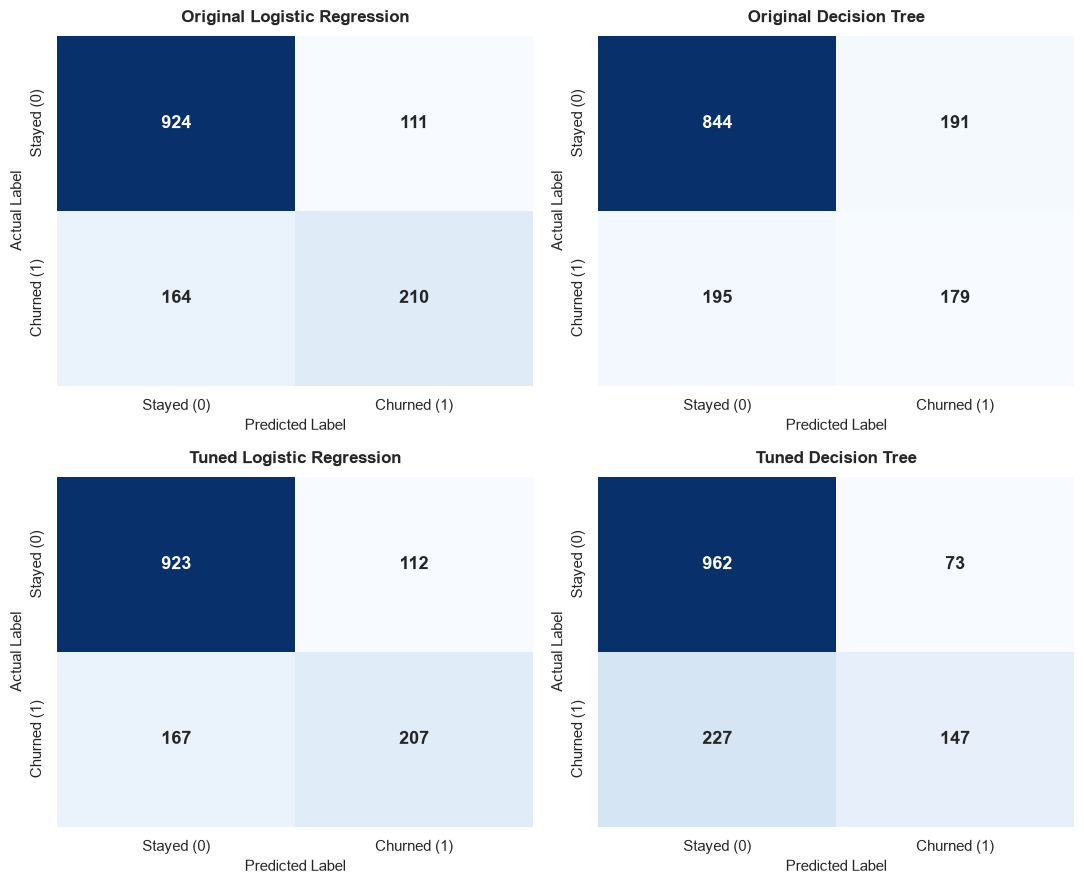

In [27]:
# Generate Confusion Matrices for all four models
cm_lr       = confusion_matrix(y_test, y_pred_lr)
cm_dt       = confusion_matrix(y_test, y_pred_dt)
cm_tuned_lr = confusion_matrix(y_test, y_pred_tuned_lr)
cm_tuned_dt = confusion_matrix(y_test, y_pred_tuned_dt)

fig, axes = plt.subplots(2, 2, figsize=(11, 9))

models_info = [
    ("Original Logistic Regression", cm_lr, axes[0, 0]),
    ("Original Decision Tree", cm_dt, axes[0, 1]),
    ("Tuned Logistic Regression", cm_tuned_lr, axes[1, 0]),
    ("Tuned Decision Tree", cm_tuned_dt, axes[1, 1])
]

for title, cm, ax in models_info:
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['Stayed (0)', 'Churned (1)'],
                yticklabels=['Stayed (0)', 'Churned (1)'],
                annot_kws={'size': 13, 'fontweight': 'bold'})
    ax.set_title(title, fontsize=12, fontweight='bold', pad=10)
    ax.set_xlabel("Predicted Label", fontsize=11)
    ax.set_ylabel("Actual Label", fontsize=11)

plt.tight_layout()
plt.show()


## 20. Classification Report

While accuracy measures overall correctness, the Classification Report provides granular evaluation metrics for each class:

### 1. Precision:
$$\text{Precision} = \frac{TP}{TP + FP}$$
* Out of all customers our model flagged as likely to churn, what percentage actually churned?
* High precision means few false alarms.

### 2. Recall (Sensitivity):
$$\text{Recall} = \frac{TP}{TP + FN}$$
* Out of all customers who actually churned, what percentage did our model successfully identify?
* **Why Recall is Critical in Churn Prediction:** A missed churner (False Negative) results in lost recurring customer revenue. A higher recall means fewer missed churners!

### 3. F1-Score:
$$\text{F1-Score} = 2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$$
* The harmonic mean of Precision and Recall. It provides a balanced single metric, especially useful on imbalanced datasets.

### 4. Support:
* The actual number of occurrences of each class in `y_test` (here: **1,035** stayed and **374** churned).

Let's generate the reports for all four models:


In [28]:
# Display classification reports for all four models
target_names = ['No Churn (0)', 'Churn (1)']

print("=======================================================")
print("1. ORIGINAL LOGISTIC REGRESSION: CLASSIFICATION REPORT")
print("=======================================================")
print(classification_report(y_test, y_pred_lr, target_names=target_names))

print("=======================================================")
print("2. ORIGINAL DECISION TREE: CLASSIFICATION REPORT")
print("=======================================================")
print(classification_report(y_test, y_pred_dt, target_names=target_names))

print("=======================================================")
print("3. TUNED LOGISTIC REGRESSION: CLASSIFICATION REPORT")
print("=======================================================")
print(classification_report(y_test, y_pred_tuned_lr, target_names=target_names))

print("=======================================================")
print("4. TUNED DECISION TREE: CLASSIFICATION REPORT")
print("=======================================================")
print(classification_report(y_test, y_pred_tuned_dt, target_names=target_names))


1. ORIGINAL LOGISTIC REGRESSION: CLASSIFICATION REPORT
              precision    recall  f1-score   support

No Churn (0)       0.85      0.89      0.87      1035
   Churn (1)       0.65      0.56      0.60       374

    accuracy                           0.80      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.80      0.80      1409

2. ORIGINAL DECISION TREE: CLASSIFICATION REPORT
              precision    recall  f1-score   support

No Churn (0)       0.81      0.82      0.81      1035
   Churn (1)       0.48      0.48      0.48       374

    accuracy                           0.73      1409
   macro avg       0.65      0.65      0.65      1409
weighted avg       0.73      0.73      0.73      1409

3. TUNED LOGISTIC REGRESSION: CLASSIFICATION REPORT
              precision    recall  f1-score   support

No Churn (0)       0.85      0.89      0.87      1035
   Churn (1)       0.65      0.55      0.60       374

    accuracy              

## 21. Model Comparison

We assemble a Pandas DataFrame summarizing all four models with their Test Accuracy, Churn Precision, Churn Recall, and Churn F1-Score, and plot a clean bar chart for visual comparison.


In [29]:
# Build Comparison DataFrame
comparison_data = {
    'Model Name': [
        'Logistic Regression (Original)',
        'Decision Tree (Original)',
        'Logistic Regression (Tuned)',
        'Decision Tree (Tuned)'
    ],
    'Test Accuracy': [
        round(acc_original_lr, 4),
        round(acc_original_dt, 4),
        round(acc_tuned_lr, 4),
        round(acc_tuned_dt, 4)
    ],
    'Churn Precision': [
        round(precision_score(y_test, y_pred_lr), 4),
        round(precision_score(y_test, y_pred_dt), 4),
        round(precision_score(y_test, y_pred_tuned_lr), 4),
        round(precision_score(y_test, y_pred_tuned_dt), 4)
    ],
    'Churn Recall': [
        round(recall_score(y_test, y_pred_lr), 4),
        round(recall_score(y_test, y_pred_dt), 4),
        round(recall_score(y_test, y_pred_tuned_lr), 4),
        round(recall_score(y_test, y_pred_tuned_dt), 4)
    ],
    'Churn F1-Score': [
        round(f1_score(y_test, y_pred_lr), 4),
        round(f1_score(y_test, y_pred_dt), 4),
        round(f1_score(y_test, y_pred_tuned_lr), 4),
        round(f1_score(y_test, y_pred_tuned_dt), 4)
    ]
}

df_comparison = pd.DataFrame(comparison_data)
print("=== Final Model Performance Comparison Table ===")
display(df_comparison)


=== Final Model Performance Comparison Table ===
                       Model Name  Test Accuracy  Churn Precision  Churn Recall  Churn F1-Score
0  Logistic Regression (Original)         0.8048           0.6542        0.5615          0.6043
1        Decision Tree (Original)         0.7260           0.4838        0.4786          0.4812
2     Logistic Regression (Tuned)         0.8020           0.6489        0.5535          0.5974
3           Decision Tree (Tuned)         0.7871           0.6682        0.3930          0.4949


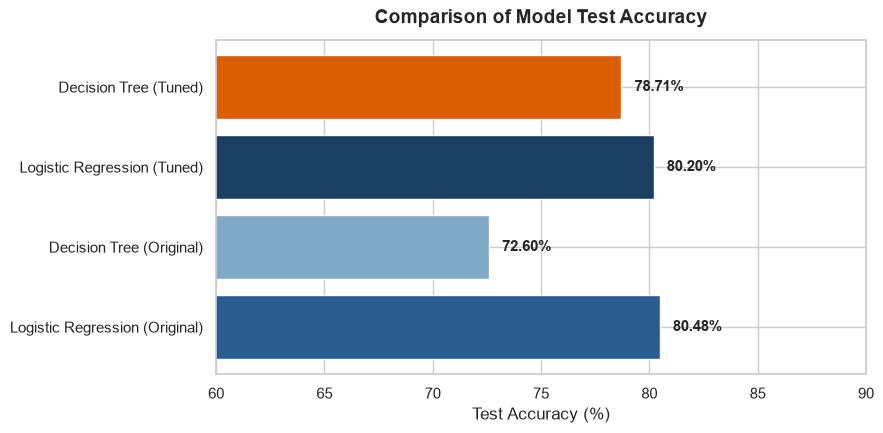

In [30]:
# Visual Comparison of Test Accuracy
fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.barh(df_comparison['Model Name'], df_comparison['Test Accuracy'] * 100, 
               color=['#2b5c8f', '#7fa9c6', '#1b3f63', '#d95f02'])

ax.set_xlim(60, 90)
ax.set_xlabel("Test Accuracy (%)", fontsize=12)
ax.set_title("Comparison of Model Test Accuracy", fontsize=14, fontweight='bold', pad=12)

# Annotate accuracy on bars
for bar in bars:
    width = bar.get_width()
    ax.annotate(f"{width:.2f}%",
                (width + 0.6, bar.get_y() + bar.get_height() / 2),
                va='center', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()


### Why Accuracy Alone is NOT Enough to Select the Best Churn Model:

In an interview or real-world deployment, relying solely on **Accuracy** can lead to disastrous business decisions. Here is why:

1. **The Class Imbalance Problem**:
   * In our test set, **73.46%** (1,035) of customers stayed, while only **26.54%** (374) churned.
   * If a naive dummy model simply predicted that **nobody ever churns** (predicts 0 for everyone), it would achieve **73.46% Accuracy**! Yet, it would catch **0 churners** and provide **zero business value**.

2. **The Business Cost of False Negatives (FN)**:
   * **False Negative (FN)**: The model predicts a customer will stay, but they actually churn. The telecom company does nothing, and the customer leaves for a competitor, resulting in hundreds of dollars in lost annual revenue and customer lifetime value (LTV).
   * **False Positive (FP)**: The model predicts a customer will churn, but they were planning to stay. The company sends them a friendly email, discount, or loyalty perk. The cost of a perk is negligible compared to losing a customer!
   * Therefore, **Recall (capturing churners)** and **F1-score** are far more critical business metrics than raw accuracy.

3. **Comparing Tuned Decision Tree vs Logistic Regression**:
   * Tuned Decision Tree achieves **78.71% accuracy**, but its Churn Recall is only **0.3930 (39.3%)**—it misses **227 out of 374 churners**!
   * Logistic Regression achieves **80.48% accuracy** and a much higher Churn Recall of **0.5615 (56.15%)**—catching **210 churners**!
   * Hence, **Logistic Regression** is clearly the superior model for business deployment.


## 22. Project Conclusion & Business Recommendations

### 1. Project Summary:
In this project, we built a complete, production-ready Customer Churn Prediction pipeline on the Telco Customer Churn dataset:
* Inspected, cleaned, and handled whitespace and missing data in `TotalCharges`.
* Dropped non-predictive identifier `customerID` to prevent data leakage.
* Visualized 6 critical customer factors driving churn.
* Encoded categorical features with `LabelEncoder` and `pd.get_dummies(drop_first=True)`.
* Split data into 80/20 train/test sets using stratification (`stratify=y`).
* Trained baseline Logistic Regression and Decision Tree models.
* Evaluated generalization with 5-Fold Cross-Validation.
* Tuned hyperparameters using `GridSearchCV` (Logistic Regression) and `RandomizedSearchCV` (Decision Tree).
* Evaluated performance across Accuracy, Confusion Matrix, Precision, Recall, and F1-Score.

### 2. Final Model Selection:
* **Champion Model:** **Logistic Regression** (Baseline / Tuned $C=10$).
* **Test Accuracy:** **80.48%** (Baseline) / **80.20%** (Tuned).
* **Churn Recall:** **56.15%** (Identifies 210 out of 374 churners in the unseen test set).
* **Churn F1-Score:** **0.60**.
* **Reason:** Provides the best balance of overall accuracy, highest recall for identifying churn risk, and stable cross-validation performance.

---

### 3. Actionable Business Recommendations for Telecom Management:
1. **Target Month-to-Month Contracts**:
   * Month-to-month customers account for the vast majority of churn (> 42%).
   * **Action**: Offer introductory discounts or loyalty perks (e.g., free speed boost, streaming subscription) to incentivize customers to sign 1-year or 2-year agreements.
2. **First 12 Months Onboarding Program**:
   * Churn peaks dramatically during the first 1 to 6 months of customer tenure.
   * **Action**: Implement a dedicated customer success check-in at 30 days and 90 days to resolve initial billing, installation, or service dissatisfaction before they churn.
3. **Migration Away from Electronic Check**:
   * Customers paying via Electronic Check churn at more than double the rate of automatic payment methods.
   * **Action**: Incentivize automated Credit Card or Bank Transfer billing by offering a small $5/month recurring discount.
4. **Targeted Value Plans for High Monthly Spenders**:
   * Churned customers pay significantly higher monthly bills (~$74 vs ~$61).
   * **Action**: Proactively identify customers paying over $80/month on month-to-month contracts and offer customized bundled packages to increase perceived value.
